# LRTS Dataset EDA and Modeling Table Decisions

This notebook profiles the LRTS source data without extracting or modifying the raw ZIP. It first audits run-level metadata across all projects, then inspects per-test outcomes, history features, code-change coverage, and candidate training rows. The final section records inclusion, exclusion, and leakage rules for the modeling table.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
ZIP_PATH = ROOT / 'data' / 'raw' / 'long_running_test_suites.zip'
FEATURES_PATH = ROOT / 'data' / 'processed' / 'features_activemq.csv.gz'
assert ZIP_PATH.is_file(), f'Missing source ZIP: {ZIP_PATH}'

with ZipFile(ZIP_PATH) as archive:
    dataset_member = 'long_running_test_suites/dataset.csv'
    assert dataset_member in archive.namelist(), f'Missing {dataset_member}'
    runs = pd.read_csv(archive.open(dataset_member))

print(f'Project root: {ROOT}')
print(f'Source ZIP size: {ZIP_PATH.stat().st_size / (1024**3):.2f} GiB (read in place)')
print(f'Run metadata shape: {runs.shape}')
print('Columns:', runs.columns.tolist())
display(runs.head())
print('\nMissing values by column:')
display(runs.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('\nDuplicate run keys (project, PR, build, stage):', int(runs.duplicated(['project', 'pr_name', 'build_id', 'stage_id']).sum()))
print('Timestamp range:', runs['build_timestamp'].min(), 'to', runs['build_timestamp'].max())

Project root: d:\TestWise
Source ZIP size: 2.81 GiB (read in place)
Run metadata shape: (108366, 16)
Columns: ['project', 'pr_name', 'pr_base_branch', 'build_id', 'build_duration', 'build_timestamp', 'build_result', 'build_head_sha', 'build_date', 'trunk_sha', 'trunk_sha_source', 'stage_id', 'test_suite_duration_s', 'num_pass_class', 'num_fail_class', 'num_trans_class']


,project,pr_name,pr_base_branch,build_id,build_duration,build_timestamp,build_result,build_head_sha,build_date,trunk_sha,trunk_sha_source,stage_id,test_suite_duration_s,num_pass_class,num_fail_class,num_trans_class
0,activemq,PR-644,main,1,5905.0,1.617292e+09,SUCCESS,a0d740aac10dd06153ece5e97f3e750dc3dd6df8,2021-04-01,85cf3476ea247bf1f182e37ea9e963a24fa58f66,build_log,single,5384.450,411,0,0
1,activemq,PR-656,main,1,5076.0,1.621851e+09,FAILURE,c7f3bd55580ca70bdb7719af2a52e162e1f557a3,2021-05-24,fd59e349aec5c5de921b2e4fb392d2b012da64ef,build_log,single,4561.209,324,1,1
2,activemq,PR-669,main,3,6493.0,1.625114e+09,SUCCESS,18437a1dfdc0dd38e7245ff398994fdf302a6ada,2021-07-01,3f5abd4433d3dca911ac418d899346e7dd675b7b,build_log,single,5699.648,412,0,1
3,activemq,PR-679,main,1,5825.0,1.625772e+09,SUCCESS,a3925c9e7973b535c18d23ae4f1bb52faec38d8e,2021-07-08,b3c2c49f96bebee14b74c6456feb233e0312724b,build_log,single,5249.749,411,0,0
4,activemq,PR-680,main,1,5156.0,1.626181e+09,FAILURE,142b0eda6fdd959e81d97f720a3511160c0b88a6,2021-07-13,b3c2c49f96bebee14b74c6456feb233e0312724b,build_log,single,4685.846,327,1,1



Missing values by column:


,missing
project,0
pr_name,0
pr_base_branch,0
build_id,0
build_duration,0
build_timestamp,0
build_result,0
build_head_sha,0
build_date,0
trunk_sha,0



Duplicate run keys (project, PR, build, stage): 0
Timestamp range: 1596073872.0 to 1713374510.0


## Dataset-Wide Coverage and Labels

Summarize project and stage coverage, time span, build outcomes, and failure prevalence. These are run-level diagnostics: the final selector will predict per-test outcomes, not the overall CI build result.

,runs,pull_requests,stages,failing_runs,failure_rows,median_tests_per_run,first_run,last_run,failing_run_rate
project,,,,,,,,,
kafka,53554,5414,24,37842,174191,1264.0,2020-11-16 22:07:52+00:00,2024-04-16 20:38:31+00:00,0.706614
tvm,40491,1742,19,5026,31750,257.0,2021-03-15 06:29:52+00:00,2024-04-17 17:21:50+00:00,0.124126
james,5838,1114,2,2528,14705,2145.0,2021-06-02 07:21:54+00:00,2024-04-16 11:08:05+00:00,0.433025
hive,2131,593,1,1472,13211,1361.0,2021-11-18 08:33:20+00:00,2024-03-12 17:07:59+00:00,0.690756
hadoop,1980,935,1,797,3968,533.0,2020-07-30 01:51:12+00:00,2024-04-16 19:52:12+00:00,0.402525
jackrabbit-oak,1654,679,1,1006,12096,1991.0,2021-07-13 15:22:26+00:00,2024-04-16 14:12:20+00:00,0.608222
hbase,1018,184,4,439,1214,1217.0,2022-03-11 08:54:42+00:00,2024-04-16 08:35:35+00:00,0.431238
karaf,726,528,1,205,416,218.0,2020-12-12 05:35:55+00:00,2024-04-08 19:23:30+00:00,0.282369
log4j,528,154,2,162,525,651.0,2020-11-17 21:57:03+00:00,2022-01-28 06:07:06+00:00,0.306818


Project-stage coverage (largest stages per project):


runs  \
project        stage_id                                             
activemq       single                                         446   
hadoop         single                                        1980   
hbase          yetus_jdk11_hadoop3_checks_precommit_checks    480   
               yetus_jdk8_Hadoop3_checks_precommit_checks     457   
               yetus_jdk17_hadoop3_checks_precommit_checks     53   
               yetus_jdk8_Hadoop2_checks_precommit_checks      28   
hive           single                                        2131   
jackrabbit-oak single                                        1654   
james          Stable_Tests                                  4353   
               Unstable_Tests                                1485   
kafka          JDK_11_and_Scala_2.13_Build                  13038   
               JDK_8_and_Scala_2.12_Build                   12761   
               JDK_17_and_Scala_2.13_Build                  10913   
               ARM_Build                                     4841   
               JDK_21_and_Scala_2.13_Build                   3070   
karaf          single                                         726   
log4j          Ubuntu_Test                                    268   
               Windows_Test                                   260   
tvm            tvm-cortexm                                   3901   
               tvm-arm                                       3616   
               tvm-i386                                      3561   
               tvm-cpu                                       3533   
               tvm-minimal                                   3395   

                                                            failing_runs  \
project        stage_id                                                    
activemq       single                                                197   
hadoop         single                                                797   
hbase          yetus_jdk11_hadoop3_checks_precommit_checks           206   
               yetus_jdk8_Hadoop3_checks_precommit_checks            196   
               yetus_jdk17_hadoop3_checks_precommit_checks            22   
               yetus_jdk8_Hadoop2_checks_precommit_checks             15   
hive           single                                               1472   
jackrabbit-oak single                                               1006   
james          Stable_Tests                                         2470   
               Unstable_Tests                                         58   
kafka          JDK_11_and_Scala_2.13_Build                         10142   
               JDK_8_and_Scala_2.12_Build                           9805   
               JDK_17_and_Scala_2.13_Build                          8917   
               ARM_Build                                            1158   
               JDK_21_and_Scala_2.13_Build                          2964   
karaf          single                                                205   
log4j          Ubuntu_Test                                            78   
               Windows_Test                                           84   
tvm            tvm-cortexm                                           276   
               tvm-arm                                               726   
               tvm-i386                                              593   
               tvm-cpu                                               608   
               tvm-minimal                                           386   

                                                            failure_rows  
project        stage_id                                                   
activemq       single                                                501  
hadoop         single                                               3968  
hbase          yetus_jdk11_hadoop3_checks_precommit_checks           551  
               yetus_jdk8_Hadoop3_checks_precommit_checks  

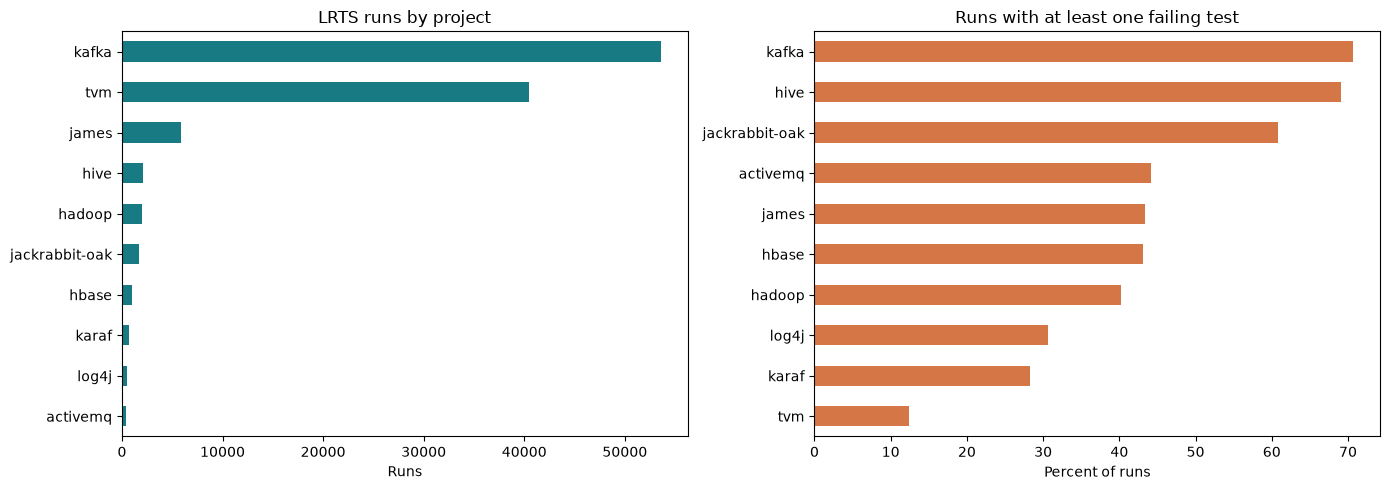

Overall run-level failure rate: 45.84%
Build result categories:


,runs
build_result,
UNSTABLE,39661
SUCCESS,33119
FAILURE,21672
NOT_BUILT,8108
ABORTED,5806


Non-positive test-count rows: 0


In [2]:
runs['build_time_utc'] = pd.to_datetime(runs['build_timestamp'], unit='s', utc=True)
runs['has_test_failure'] = runs['num_fail_class'].gt(0)
runs['reported_test_count'] = runs['num_pass_class'] + runs['num_fail_class']

project_summary = runs.groupby('project').agg(
    runs=('build_id', 'size'),
    pull_requests=('pr_name', 'nunique'),
    stages=('stage_id', 'nunique'),
    failing_runs=('has_test_failure', 'sum'),
    failure_rows=('num_fail_class', 'sum'),
    median_tests_per_run=('reported_test_count', 'median'),
    first_run=('build_time_utc', 'min'),
    last_run=('build_time_utc', 'max'),
).sort_values('runs', ascending=False)
project_summary['failing_run_rate'] = project_summary['failing_runs'] / project_summary['runs']
display(project_summary)

stage_summary = (runs.groupby(['project', 'stage_id'], observed=True)
                 .agg(runs=('build_id', 'size'), failing_runs=('has_test_failure', 'sum'),
                      failure_rows=('num_fail_class', 'sum'))
                 .sort_values(['project', 'runs'], ascending=[True, False]))
print('Project-stage coverage (largest stages per project):')
display(stage_summary.groupby(level=0, group_keys=False).head(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
project_summary['runs'].sort_values().plot.barh(ax=axes[0], color='#187b83')
axes[0].set(title='LRTS runs by project', xlabel='Runs', ylabel='')
(project_summary['failing_run_rate'].sort_values() * 100).plot.barh(ax=axes[1], color='#d47645')
axes[1].set(title='Runs with at least one failing test', xlabel='Percent of runs', ylabel='')
fig.tight_layout()
plt.show()

print('Overall run-level failure rate:', f"{runs['has_test_failure'].mean():.2%}")
print('Build result categories:')
display(runs['build_result'].value_counts(dropna=False).to_frame('runs'))
print('Non-positive test-count rows:', int(runs['reported_test_count'].le(0).sum()))

## ActiveMQ Per-Test Table: Quality and Leakage Audit

ActiveMQ is the current end-to-end feature table in this workspace. Validate row identity, label balance, run-level row counts, code-change coverage, and the temporal construction of history/duration features before treating it as a training dataset.

In [4]:
import sys

assert FEATURES_PATH.is_file(), f'Missing processed feature table: {FEATURES_PATH}'
features = pd.read_csv(FEATURES_PATH)
feature_cols = ['last_outcome', 'prior_runs', 'prior_fails', 'fail_rate', 'fails_last5',
                'fails_last20', 'runs_since_fail', 'last_duration', 'mean_duration',
                'test_class_changed', 'same_pkg', 'pkg_overlap_depth', 'name_match',
                'n_files', 'additions', 'deletions', 'n_java', 'n_test_files', 'n_pom']
post_run_forbidden = {'build_result', 'build_duration', 'test_suite_duration_s',
                      'num_pass_class', 'num_fail_class', 'num_trans_class', 'duration'}
assert not (set(feature_cols) & post_run_forbidden), 'A post-run field is in the candidate feature list'
assert set(feature_cols).issubset(features.columns), 'Feature table is missing candidate features'

features['run_key'] = features['pr_name'].astype(str) + '_build' + features['build_id'].astype(str)
features['first_seen_test'] = features['prior_runs'].eq(0)
features['ever_failed_before'] = features['prior_fails'].gt(0)

print('Notebook interpreter:', sys.executable)
print('Feature table shape:', features.shape)
print('Unique runs:', features['run_idx'].nunique(), '| unique test classes:', features['testclass'].nunique())
print('Duplicate (run_idx, testclass) rows:', int(features.duplicated(['run_idx', 'testclass']).sum()))
print('Missing values in feature/label columns:')
display(features[feature_cols + ['outcome']].isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Test-row failures:', int(features['outcome'].sum()), '| row failure rate:', f"{features['outcome'].mean():.4%}")
print('Runs with failures:', int(features.groupby('run_idx')['outcome'].max().sum()), 'of', features['run_idx'].nunique())
print('Failures in first-ever test appearances:', int((features['outcome'].eq(1) & features['first_seen_test']).sum()))

amq_meta = runs[runs['project'].eq('activemq')].copy()
amq_meta = amq_meta.sort_values('build_timestamp', kind='stable').reset_index(drop=True)
amq_meta['run_idx'] = amq_meta.index
run_counts = features.groupby('run_idx').size().rename('observed_test_rows')
amq_meta = amq_meta.set_index('run_idx')
consistency = run_counts.to_frame().join((amq_meta['num_pass_class'] + amq_meta['num_fail_class']).rename('metadata_test_rows'))
consistency['matches'] = consistency['observed_test_rows'].eq(consistency['metadata_test_rows'])
print('Per-run test rows match metadata:', f"{consistency['matches'].mean():.2%}",
      f"({int(consistency['matches'].sum())}/{len(consistency)})")
print('Mismatching ActiveMQ runs:')
display(consistency.loc[~consistency['matches']].head(10))

changes_path = ROOT / 'data' / 'processed' / 'code_changes_activemq.csv'
if changes_path.is_file():
    code_changes = pd.read_csv(changes_path)
    changed_keys = set(code_changes['run_key'].astype(str))
    print('Runs with code-change data:', f"{features.groupby('run_idx')['run_key'].first().isin(changed_keys).mean():.2%}")
else:
    print('Code-change cache not found:', changes_path)

rate_by_history = (features.groupby('ever_failed_before')['outcome']
                   .agg(rows='size', failures='sum', failure_rate='mean'))
display(rate_by_history)
rate_by_first_seen = (features.groupby('first_seen_test')['outcome']
                      .agg(rows='size', failures='sum', failure_rate='mean'))
display(rate_by_first_seen)

print('Candidate model features:', feature_cols)
print('Observed leakage columns are metadata only, not in candidate features:', sorted(post_run_forbidden & set(features.columns)))

Notebook interpreter: d:\retail-sales-etl\.venv\Scripts\python.exe
Feature table shape: (379243, 30)
Unique runs: 446 | unique test classes: 1126
Duplicate (run_idx, testclass) rows: 0
Missing values in feature/label columns:


,missing
last_outcome,0
prior_runs,0
prior_fails,0
fail_rate,0
fails_last5,0
fails_last20,0
runs_since_fail,0
last_duration,0
mean_duration,0
test_class_changed,0


Test-row failures: 501 | row failure rate: 0.1321%
Runs with failures: 197 of 446
Failures in first-ever test appearances: 4
Per-run test rows match metadata: 100.00% (446/446)
Mismatching ActiveMQ runs:


,observed_test_rows,metadata_test_rows,matches
run_idx,,,


Runs with code-change data: 100.00%


,rows,failures,failure_rate
ever_failed_before,,,
False,333818,154,0.000461
True,45425,347,0.007639


,rows,failures,failure_rate
first_seen_test,,,
False,378117,497,0.001314
True,1126,4,0.003552


Candidate model features: ['last_outcome', 'prior_runs', 'prior_fails', 'fail_rate', 'fails_last5', 'fails_last20', 'runs_since_fail', 'last_duration', 'mean_duration', 'test_class_changed', 'same_pkg', 'pkg_overlap_depth', 'name_match', 'n_files', 'additions', 'deletions', 'n_java', 'n_test_files', 'n_pom']
Observed leakage columns are metadata only, not in candidate features: ['build_result']


## Failure Structure and Run Completeness

Measure how concentrated failures are across test classes, how much history is available, and whether CI statuses suggest incomplete runs. `build_result` is used only for this audit; it must not be an online prediction feature because it is known only after execution.

Top 10 classes by historical failures:


,failures,appearances,failure_share
testclass,,,
org.apache.activemq.bugs.AMQ6815Test,57,383,0.113772
org.apache.activemq.advisory.AdvisoryTests,23,373,0.045908
org.apache.activemq.config.BrokerXmlConfigStartTest,23,240,0.045908
org.apache.activemq.bugs.AMQ6131Test,23,386,0.045908
org.apache.activemq.bugs.AMQ7118Test,16,375,0.031936
org.apache.activemq.broker.LinkStealingTest,15,444,0.029940
org.apache.activemq.broker.OpenwireConnectionTest,15,444,0.029940
org.apache.activemq.store.kahadb.MultiKahaDBMessageStoreSizeStatTest,13,375,0.025948
org.apache.activemq.usecases.TwoBrokersStopSlaveTest,9,371,0.017964


Failure concentration in top 10 classes: 40.1%
Run completeness by post-run CI status (audit only):


,runs,median_test_rows,min_test_rows,max_test_rows,failing_runs,failures,failing_run_rate
build_result,,,,,,,
ABORTED,26,512.0,3,863,9,53,0.346154
FAILURE,203,875.0,57,1016,188,448,0.926108
SUCCESS,217,1014.0,382,1025,0,0,0.000000


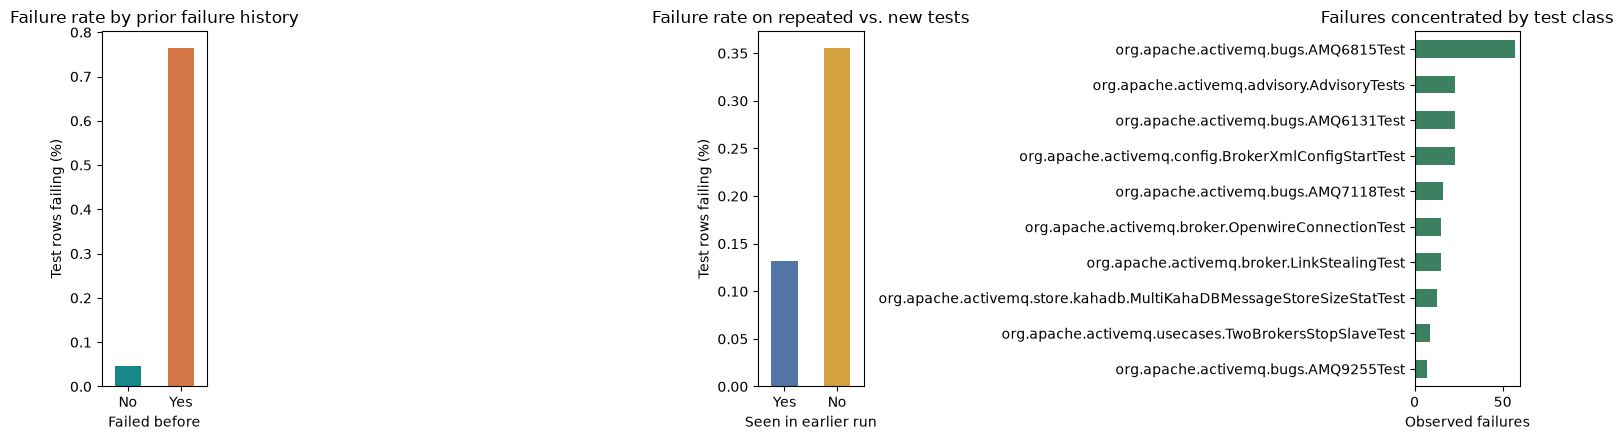

In [5]:
class_failures = (features.groupby('testclass')['outcome'].agg(failures='sum', appearances='size')
                  .sort_values('failures', ascending=False))
class_failures['failure_share'] = class_failures['failures'] / max(int(features['outcome'].sum()), 1)
print('Top 10 classes by historical failures:')
display(class_failures.head(10))
print('Failure concentration in top 10 classes:', f"{class_failures.head(10)['failure_share'].sum():.1%}")

run_metrics = (features.groupby(['run_idx', 'build_result'], as_index=False)
               .agg(test_rows=('outcome', 'size'), failures=('outcome', 'sum')))
status_summary = run_metrics.groupby('build_result').agg(
    runs=('run_idx', 'nunique'),
    median_test_rows=('test_rows', 'median'),
    min_test_rows=('test_rows', 'min'),
    max_test_rows=('test_rows', 'max'),
    failing_runs=('failures', lambda values: int((values > 0).sum())),
    failures=('failures', 'sum'),
)
status_summary['failing_run_rate'] = status_summary['failing_runs'] / status_summary['runs']
print('Run completeness by post-run CI status (audit only):')
display(status_summary)

history_plot = rate_by_history['failure_rate'].reindex([False, True]) * 100
first_plot = rate_by_first_seen['failure_rate'].reindex([False, True]) * 100
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
history_plot.plot.bar(ax=axes[0], color=['#17878a', '#d47645'])
axes[0].set(title='Failure rate by prior failure history', ylabel='Test rows failing (%)', xlabel='Failed before')
axes[0].set_xticklabels(['No', 'Yes'], rotation=0)
first_plot.plot.bar(ax=axes[1], color=['#5176a5', '#d4a23f'])
axes[1].set(title='Failure rate on repeated vs. new tests', ylabel='Test rows failing (%)', xlabel='Seen in earlier run')
axes[1].set_xticklabels(['Yes', 'No'], rotation=0)
class_failures.head(10)['failures'].sort_values().plot.barh(ax=axes[2], color='#3a8061')
axes[2].set(title='Failures concentrated by test class', xlabel='Observed failures', ylabel='')
fig.tight_layout()
plt.show()

## Finalize ActiveMQ Modeling and Evaluation Table

The existing feature table omits current test duration, which is needed to measure execution-time savings but is forbidden as a same-run prediction feature. Rebuild a separate v1 table by joining the observed duration from each raw test-result file onto the existing feature rows. Preserve all observed test results, add explicit model/evaluation field lists, and leave the existing feature file untouched.

In [7]:
import io
from zipfile import ZipFile

# Restore only the evaluation cost (observed test duration) from the raw result files.
duration_parts = []
with ZipFile(ZIP_PATH) as archive:
    for run in amq_meta.reset_index().itertuples(index=False):
        result_member = (f"long_running_test_suites/processed_test_result/activemq/"
                        f"{run.pr_name}_build{run.build_id}/stage_{run.stage_id}/test_class.csv.zip")
        with ZipFile(io.BytesIO(archive.read(result_member))) as result_zip:
            test_result = pd.read_csv(result_zip.open('test_class.csv'),
                                      usecols=['testclass', 'duration', 'outcome'])
        test_result['run_idx'] = run.run_idx
        duration_parts.append(test_result)

raw_test_results = pd.concat(duration_parts, ignore_index=True)
raw_test_results = (raw_test_results.groupby(['run_idx', 'testclass'], as_index=False)
                    .agg(duration=('duration', 'sum'), raw_outcome=('outcome', 'max')))

final_table = features.merge(raw_test_results, on=['run_idx', 'testclass'], how='left', validate='one_to_one')
assert final_table['duration'].notna().all(), 'Duration join left missing rows'
assert final_table['outcome'].eq(final_table['raw_outcome']).all(), 'Label mismatch with raw results'
assert len(final_table) == len(features), 'The join changed observed-row count'

IDENTIFIERS = ['project', 'pr_name', 'build_id', 'stage_id', 'run_idx', 'testclass']
LABEL = ['outcome']
MODEL_FEATURES = feature_cols
EVALUATION_ONLY = ['duration', 'build_date', 'build_result']
METADATA_ONLY = ['raw_outcome', 'run_key']
FINAL_COLUMNS = IDENTIFIERS + LABEL + MODEL_FEATURES + EVALUATION_ONLY + METADATA_ONLY
final_table['project'] = 'activemq'
final_table = final_table[FINAL_COLUMNS].sort_values(['run_idx', 'testclass']).reset_index(drop=True)

assert final_table.duplicated(['run_idx', 'testclass']).sum() == 0
assert final_table[MODEL_FEATURES + LABEL + ['duration']].notna().all().all()
assert not set(MODEL_FEATURES).intersection(EVALUATION_ONLY)
assert (final_table['duration'] >= 0).all()

OUT_PATH = ROOT / 'data' / 'processed' / 'modeling_table_activemq_v1.csv.gz'
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
final_table.to_csv(OUT_PATH, index=False, compression='gzip')

print('Saved finalized ActiveMQ table:', OUT_PATH)
print('Shape:', final_table.shape)
print('Unique runs:', final_table['run_idx'].nunique(), '| unique tests:', final_table['testclass'].nunique())
print('Failure rows:', int(final_table['outcome'].sum()), '| failure rate:', f"{final_table['outcome'].mean():.4%}")
print('Median observed duration (seconds):', round(final_table['duration'].median(), 3))
print('Model feature count:', len(MODEL_FEATURES))
print('Evaluation-only fields:', EVALUATION_ONLY)
print('Post-run summary fields excluded from model inputs:', sorted(post_run_forbidden))
print('Output bytes:', OUT_PATH.stat().st_size)

Saved finalized ActiveMQ table: d:\TestWise\data\processed\modeling_table_activemq_v1.csv.gz
Shape: (379243, 31)
Unique runs: 446 | unique tests: 1126
Failure rows: 501 | failure rate: 0.1321%
Median observed duration (seconds): 3.125
Model feature count: 19
Evaluation-only fields: ['duration', 'build_date', 'build_result']
Post-run summary fields excluded from model inputs: ['build_duration', 'build_result', 'duration', 'num_fail_class', 'num_pass_class', 'num_trans_class', 'test_suite_duration_s']
Output bytes: 10193383


## Findings and v1 Data Decisions

### Q&A

- The source metadata has 108,366 runs across 10 projects, 16 columns, no missing values, and no duplicate `(project, PR, build, stage)` keys. Timestamps span 2020-07-30 through 2024-04-17.
- Failures are rare per test row but common at the run level: ActiveMQ has 501 failing test rows among 379,243 rows (0.1321%), across 197 of 446 runs.
- The ActiveMQ v1 table is saved at `data/processed/modeling_table_activemq_v1.csv.gz`. It contains one row per observed `(run_idx, testclass)`, labels from the raw test-result files, 19 candidate features, and current observed duration for evaluation only.

### Data Analysis Key Findings

- Kafka (53,554 runs) and TVM (40,491) account for 86.8% of all runs. Run-level failure prevalence varies substantially by project, so pooled metrics must be reported by project and evaluated with project-held-out tests.
- ActiveMQ has no missing candidate features, duplicate test rows, or code-change coverage gaps; all 446 run row counts match run metadata.
- Prior-failed ActiveMQ tests fail at 0.764% versus 0.046% for tests with no prior failures. The top 10 classes account for 40.1% of observed failures. Only four failures occur on a class's first appearance, so ActiveMQ provides little evidence about truly new tests.
- Current-run duration and run/build summaries are post-run information. Duration is retained for cost evaluation but excluded from `MODEL_FEATURES`; `build_result`, `build_duration`, `test_suite_duration_s`, and `num_*_class` must likewise never be prediction inputs.

### Insights or Next Steps

- Treat this as the **ActiveMQ pilot table**, not a finalized universal LRTS training corpus. Keep `project`, `stage_id`, `run_idx`, PR, build, and test identifiers for grouping, time splits, and held-out evaluation. For multi-stage projects, history must be keyed by `(project, stage, test)` rather than test name alone.
- Preserve every observed test row in the curated table. For offline selection metrics, separately require a fully observed suite/run; audit `ABORTED`, `NOT_BUILT`, and unusually low test counts rather than silently treating skipped tests as passes. Report test-row and failing-run metrics by project/stage.
- Before training the cross-project model, build the same language-agnostic schema for more projects, then use chronological splits with PR purging and project-held-out evaluation. Use full-suite outcomes as ground truth for selection-policy comparisons.

The raw ZIP and existing feature table remain unchanged. The final table is a new, reproducible derived artifact.

## Cross-Project Raw Test Record Compatibility

Before materializing a broader corpus, sample the first, middle, and last runs in every project/stage. Check that the raw test files share the required target and cost fields, verify labels/durations, and summarize code-diff availability by project. This is a schema/coverage check, not a replacement for full-data validation.

In [8]:
import io
from zipfile import ZipFile

sample_indices = []
for _, group in runs.sort_values('build_timestamp', kind='stable').groupby(['project', 'stage_id'], observed=True):
    ordered_indices = group.index.to_list()
    sample_indices.extend([ordered_indices[0], ordered_indices[len(ordered_indices) // 2], ordered_indices[-1]])
sample_runs = runs.loc[sorted(set(sample_indices))]

schema_results = []
with ZipFile(ZIP_PATH) as archive:
    for row in sample_runs.itertuples(index=False):
        result_path = (f"long_running_test_suites/processed_test_result/{row.project}/"
                       f"{row.pr_name}_build{row.build_id}/stage_{row.stage_id}/test_class.csv.zip")
        try:
            with ZipFile(io.BytesIO(archive.read(result_path))) as nested:
                result = pd.read_csv(nested.open('test_class.csv'))
            schema_results.append({
                'project': row.project, 'stage_id': row.stage_id, 'build_id': row.build_id,
                'rows': len(result), 'columns': tuple(result.columns),
                'has_testclass': 'testclass' in result,
                'has_outcome': 'outcome' in result,
                'has_duration': 'duration' in result,
                'missing_test_id': int(result['testclass'].isna().sum()) if 'testclass' in result else None,
                'missing_outcome': int(result['outcome'].isna().sum()) if 'outcome' in result else None,
                'missing_duration': int(result['duration'].isna().sum()) if 'duration' in result else None,
                'outcome_values': tuple(sorted(pd.to_numeric(result['outcome'], errors='coerce').dropna().unique())) if 'outcome' in result else None,
            })
        except KeyError:
            schema_results.append({'project': row.project, 'stage_id': row.stage_id,
                                   'build_id': row.build_id, 'missing_file': result_path})

schema_sample = pd.DataFrame(schema_results)
print('Sampled run files:', len(schema_sample))
print('Required columns present in every sampled file:',
      bool(schema_sample[['has_testclass', 'has_outcome', 'has_duration']].all().all()))
print('Distinct column layouts:', schema_sample['columns'].nunique())
print('Sample label domains:', schema_sample['outcome_values'].dropna().unique().tolist())
display(schema_sample.groupby('project').agg(
    sampled_files=('build_id', 'size'),
    schema_layouts=('columns', 'nunique'),
    missing_testclass=('missing_test_id', 'sum'),
    missing_outcome=('missing_outcome', 'sum'),
    missing_duration=('missing_duration', 'sum'),
))

with ZipFile(ZIP_PATH) as archive:
    names = archive.namelist()
compare_paths = [name for name in names if '/shadata/' in name and '/compare_commits/' in name and name.endswith('.json')]
compare_rows = []
for project in sorted(runs['project'].unique()):
    project_runs = runs[runs['project'].eq(project)]
    project_prefix = f'/shadata/{project}/compare_commits/'
    project_compare_paths = [name for name in compare_paths if project_prefix in name]
    compare_keys = {name.split('/')[4] for name in project_compare_paths if len(name.split('/')) > 4}
    run_keys = set(project_runs['pr_name'].astype(str) + '_build' + project_runs['build_id'].astype(str))
    compare_rows.append({'project': project, 'runs': len(project_runs),
                         'runs_with_compare_json': len(run_keys & compare_keys),
                         'coverage': len(run_keys & compare_keys) / len(run_keys) if run_keys else 0})
compare_coverage = pd.DataFrame(compare_rows).set_index('project').sort_values('runs', ascending=False)
display(compare_coverage)

Sampled run files: 162
Required columns present in every sampled file: True
Distinct column layouts: 1
Sample label domains: [(np.int64(0),), (np.int64(0), np.int64(1))]


,sampled_files,schema_layouts,missing_testclass,missing_outcome,missing_duration
project,,,,,
activemq,3,1,0,0,0
hadoop,3,1,0,0,0
hbase,12,1,0,0,0
hive,3,1,0,0,0
jackrabbit-oak,3,1,0,0,0
james,6,1,0,0,0
kafka,66,1,0,0,0
karaf,3,1,0,0,0
log4j,6,1,0,0,0


,runs,runs_with_compare_json,coverage
project,,,
kafka,53554,16088,1.0
tvm,40491,6512,1.0
james,5838,4353,1.0
hive,2131,2131,1.0
hadoop,1980,1980,1.0
jackrabbit-oak,1654,1654,1.0
hbase,1018,485,1.0
karaf,726,726,1.0
log4j,528,270,1.0
